[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SinaGhanbarii/gasmem/blob/main/notebooks/02_cross_flow.ipynb)

# 2 · Cross-flow model

The feed moves in plug flow; the permeate leaves each element straight away, without mixing
along the module. Each element therefore releases permeate of the **local** composition
$y(x)$, the solution of $y_i = J_i / \sum J$ with $J_i = Q_i (p_h x_i - p_l y_i)$.

Using the retentate flow $L$ as the independent variable makes the stage cut an input:

$$\frac{dN_i}{dL} = y_i(x), \qquad \frac{dA}{dL} = -\frac{1}{J_{tot}}, \qquad L: F \rightarrow (1-\theta)F$$

**Weller & Steiner (1950)** integrated the binary case analytically. The closed form is coded in
`weller_steiner()` and used here as an independent check of the numerical model.

In [1]:
\
# --- Find the toolkit (works on your own computer and in Google Colab) ---
import sys, os, glob, pathlib

def _find_toolkit():
    here = pathlib.Path.cwd()
    for p in [here, *here.parents]:                       # running from inside the folder
        if (p / "gasmem" / "__init__.py").exists():
            return p
    for pat in ["/content/*/gasmem/__init__.py",           # Colab: repository cloned into /content
                "/content/drive/MyDrive/gasmem/__init__.py",
                "/content/drive/MyDrive/*/gasmem/__init__.py",
                "/content/drive/MyDrive/*/*/gasmem/__init__.py",
                "/content/drive/MyDrive/*/*/*/gasmem/__init__.py"]:
        hits = sorted(glob.glob(pat))
        if hits:
            return pathlib.Path(hits[0]).parents[1]
    return None

TOOLKIT = _find_toolkit()
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

REPO = "https://github.com/SinaGhanbarii/gasmem.git"
if TOOLKIT is None and IN_COLAB:
    # opened from the "Open in Colab" badge: fetch the toolkit from GitHub
    import subprocess
    print("Downloading the toolkit from", REPO)
    if subprocess.run(["git", "clone", "-q", "--depth", "1", REPO, "/content/gasmem"]).returncode:
        print("Download failed; looking in your Google Drive instead (approve the access request)")
        from google.colab import drive
        drive.mount("/content/drive")
    TOOLKIT = _find_toolkit()
if IN_COLAB:
    from google.colab import output
    output.enable_custom_widget_manager()               # makes the sliders work in Colab
if TOOLKIT is None:
    raise FileNotFoundError("Could not find the 'gasmem' folder. Open this notebook from inside "
                            "your copy of the repository (git clone " + REPO + ").")
sys.path.insert(0, str(TOOLKIT))
os.chdir(TOOLKIT / "notebooks")
print("Using toolkit at", TOOLKIT)
# ---------------------------------------------------------------------------

import numpy as np, pandas as pd, matplotlib.pyplot as plt
import ipywidgets as w
from IPython.display import display, Markdown
from gasmem import *
import gasmem.plotting as gasmem_plot
from gasmem.plotting import (plot_stage_cut_tradeoff, plot_purity_recovery, plot_profiles,
                             bar_breakdown, COLORS, MARKERS)
pd.set_option("display.precision", 4)

Using toolkit at /home/claude/gas-membrane-stagecut-toolkit


## Numerical model versus Weller–Steiner

In [2]:
alpha, phi, xf = 10, 4, 0.209
rows = []
for th in (0.05, 0.2, 0.4, 0.6, 0.8, 0.95):
    xo, yp = weller_steiner_theta(alpha, phi, xf, th)
    r = cross_flow(Membrane.binary(alpha), [xf, 1 - xf], th, phi, 1.0, profile=False)
    rows.append(dict(theta=th, y_analytical=yp, y_numerical=r.y_perm[0],
                     x_analytical=xo, x_numerical=r.x_ret[0],
                     max_abs_difference=max(abs(yp - r.y_perm[0]), abs(xo - r.x_ret[0]))))
pd.DataFrame(rows).style.format({"max_abs_difference": "{:.1e}"}, precision=5)

,theta,y_analytical,y_numerical,x_analytical,x_numerical,max_abs_difference
0,0.05000,0.51532,0.51532,0.19288,0.19288,1.8e-11
1,0.20000,0.46518,0.46518,0.14496,0.14496,2.7e-10
2,0.40000,0.39348,0.39348,0.08601,0.08601,6.0e-11
3,0.60000,0.32231,0.32231,0.03904,0.03904,1.4e-10
4,0.80000,0.25887,0.25887,0.00953,0.00953,3.9e-11
5,0.95000,0.21997,0.21997,0.00054,0.00054,8.6e-12


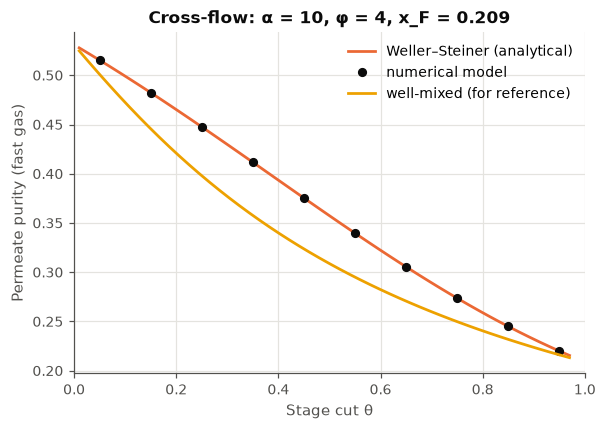

In [3]:
th = np.linspace(0.01, 0.97, 50)
fig, ax = plt.subplots(figsize=(5.4, 3.8), constrained_layout=True)
ax.plot(th, [weller_steiner_theta(alpha, phi, xf, t)[1] for t in th], color=COLORS["cross_flow"],
        label="Weller–Steiner (analytical)")
ths = np.linspace(0.05, 0.95, 10)
ax.plot(ths, [cross_flow(Membrane.binary(alpha), [xf, 1 - xf], t, phi, 1.0, profile=False).y_perm[0]
              for t in ths], ls="none", marker="o", color="#0b0b0b", ms=5, label="numerical model")
ax.plot(th, [well_mixed_binary(alpha, phi, xf, t)["y"] for t in th], color=COLORS["well_mixed"],
        label="well-mixed (for reference)")
ax.set(xlabel="Stage cut θ", ylabel="Permeate purity (fast gas)", xlim=(0, 1),
       title="Cross-flow: α = 10, φ = 4, x_F = 0.209"); ax.legend();

## Interactive: cross-flow against the well-mixed baseline

In [4]:
def explore(alpha=10.0, phi=4.0, x_feed=0.2, theta=0.4):
    df = binary_sweep(alpha, phi, x_feed, np.linspace(0.02, 0.95, 28), ["well_mixed", "cross_flow"])
    plot_stage_cut_tradeoff(df, "A", "area_dimless", ["well_mixed", "cross_flow"], theta_now=theta,
                            area_label="A·Q_A·p_h / F"); plt.show()
    r = cross_flow(Membrane.binary(alpha), [x_feed, 1 - x_feed], theta, phi, 1.0)
    plot_profiles({"cross_flow": r}, "A", title="Along the module: feed side and local permeate"); plt.show()

w.interact(explore,
           alpha=w.FloatSlider(value=10, min=1.5, max=100, step=0.5, continuous_update=False, description="α"),
           phi=w.FloatSlider(value=4, min=1.2, max=100, step=0.2, continuous_update=False, description="φ"),
           x_feed=w.FloatSlider(value=0.2, min=0.02, max=0.9, step=0.01, continuous_update=False, description="x feed"),
           theta=w.FloatSlider(value=0.4, min=0.02, max=0.95, step=0.01, continuous_update=False, description="θ"));

interactive(children=(FloatSlider(value=10.0, continuous_update=False, description='α', min=1.5, step=0.5), Fl…

**Takeaway.** Near the feed inlet the cross-flow module produces permeate much richer than the
average, so for the same stage cut the collected permeate is purer, and slightly less area is
needed, than in a well-mixed stage.